## Global Happiness Analysis: Economic and Social Factors Influencing Life Satisfaction (2005–2023)

## Introduction

This project explores global life satisfaction across countries from 2005 to 2023, using data from the World Happiness Report.

The analysis focuses on changes in life satisfaction over time and its relationships with economic and social indicators, including GDP per capita, social support, perceived corruption, and emotional well-being.

The main objective is to identify patterns, compare countries, and understand how different indicators are associated with life satisfaction.

Tools: Python, Pandas, Matplotlib, Seaborn.

Dataset link:
https://www.kaggle.com/datasets/jainaru/world-happiness-report-2024-yearly-updated

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Data loading and Dataset Description

In [2]:
df = pd.read_csv(
    "../data/World-happiness-report-updated_2024.csv",
    encoding="cp1252"
)
print(df.head())

  Country name  year  Life Ladder  Log GDP per capita  Social support  \
0  Afghanistan  2008        3.724               7.350           0.451   
1  Afghanistan  2009        4.402               7.509           0.552   
2  Afghanistan  2010        4.758               7.614           0.539   
3  Afghanistan  2011        3.832               7.581           0.521   
4  Afghanistan  2012        3.783               7.661           0.521   

   Healthy life expectancy at birth  Freedom to make life choices  Generosity  \
0                              50.5                         0.718       0.164   
1                              50.8                         0.679       0.187   
2                              51.1                         0.600       0.118   
3                              51.4                         0.496       0.160   
4                              51.7                         0.531       0.234   

   Perceptions of corruption  Positive affect  Negative affect  
0        

In [3]:
print("Shape of data:", df.shape)
print("Columns:", df.columns)
print("Index Range:", df.index)
print(df.dtypes)

Shape of data: (2363, 11)
Columns: Index(['Country name', 'year', 'Life Ladder', 'Log GDP per capita',
       'Social support', 'Healthy life expectancy at birth',
       'Freedom to make life choices', 'Generosity',
       'Perceptions of corruption', 'Positive affect', 'Negative affect'],
      dtype='str')
Index Range: RangeIndex(start=0, stop=2363, step=1)
Country name                            str
year                                  int64
Life Ladder                         float64
Log GDP per capita                  float64
Social support                      float64
Healthy life expectancy at birth    float64
Freedom to make life choices        float64
Generosity                          float64
Perceptions of corruption           float64
Positive affect                     float64
Negative affect                     float64
dtype: object


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2363 entries, 0 to 2362
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country name                      2363 non-null   str    
 1   year                              2363 non-null   int64  
 2   Life Ladder                       2363 non-null   float64
 3   Log GDP per capita                2335 non-null   float64
 4   Social support                    2350 non-null   float64
 5   Healthy life expectancy at birth  2300 non-null   float64
 6   Freedom to make life choices      2327 non-null   float64
 7   Generosity                        2282 non-null   float64
 8   Perceptions of corruption         2238 non-null   float64
 9   Positive affect                   2339 non-null   float64
 10  Negative affect                   2347 non-null   float64
dtypes: float64(9), int64(1), str(1)
memory usage: 222.3 KB


In [5]:
df.isnull().sum()

Country name                          0
year                                  0
Life Ladder                           0
Log GDP per capita                   28
Social support                       13
Healthy life expectancy at birth     63
Freedom to make life choices         36
Generosity                           81
Perceptions of corruption           125
Positive affect                      24
Negative affect                      16
dtype: int64

In [6]:
df.describe().round(3)

,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
count,2363.000,2363.000,2335.000,2350.000,2300.000,2327.000,2282.000,2238.000,2339.000,2347.000
mean,2014.764,5.484,9.400,0.809,63.402,0.750,0.000,0.744,0.652,0.273
std,5.059,1.126,1.152,0.121,6.843,0.139,0.161,0.185,0.106,0.087
min,2005.000,1.281,5.527,0.228,6.720,0.228,-0.340,0.035,0.179,0.083
25%,2011.000,4.647,8.506,0.744,59.195,0.661,-0.112,0.687,0.572,0.209
50%,2015.000,5.449,9.503,0.834,65.100,0.771,-0.022,0.798,0.663,0.262
75%,2019.000,6.324,10.392,0.904,68.552,0.862,0.094,0.868,0.737,0.326
max,2023.000,8.019,11.676,0.987,74.600,0.985,0.700,0.983,0.884,0.705


In [7]:
print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate country-year pairs:",
    df.duplicated(subset=["Country name", "year"]).sum()
)

Duplicate rows: 0
Duplicate country-year pairs: 0


## 2. Happiness Rankings
The happiest countries 2005-2023 based on the average Life Ladder

In [8]:
happiness_ranking = (
    df.groupby("Country name")["Life Ladder"]
    .agg(
        mean_happiness = "mean",
        years_available = "count",
        std_happiness = "std"
    )
    .query("years_available >= 10")
    .sort_values("mean_happiness", ascending=False)
    .round(3)
)

print(happiness_ranking.head(10))

              mean_happiness  years_available  std_happiness
Country name                                                
Denmark                7.664               18          0.159
Finland                7.624               16          0.185
Iceland                7.468               11          0.197
Norway                 7.464               13          0.142
Netherlands            7.440               17          0.098
Switzerland            7.436               13          0.252
Sweden                 7.365               18          0.106
Canada                 7.297               18          0.242
New Zealand            7.261               17          0.151
Australia              7.242               17          0.119


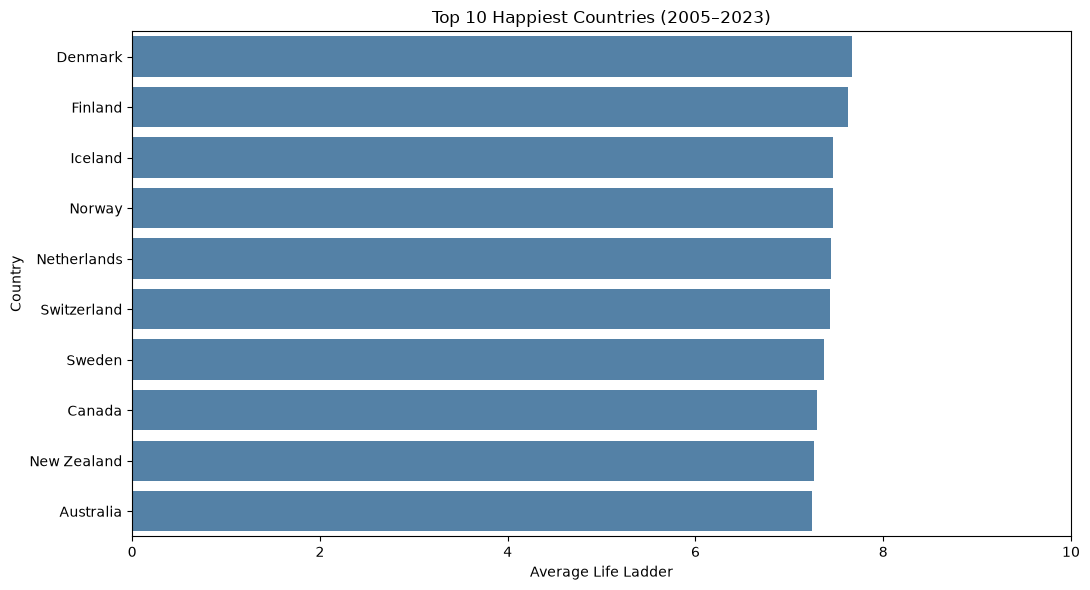

In [9]:
top10_historical = happiness_ranking.head(10).reset_index()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top10_historical,
    x="mean_happiness",
    y="Country name",
    color="steelblue"
)

plt.title("Top 10 Happiest Countries (2005–2023)")
plt.xlabel("Average Life Ladder")
plt.ylabel("Country")
plt.xlim(0, 10)

plt.tight_layout()
plt.show()

In [10]:
print(happiness_ranking.tail(10))

              mean_happiness  years_available  std_happiness
Country name                                                
Haiti                  3.954               11          0.467
Sierra Leone           3.939               15          0.668
Malawi                 3.928               15          0.575
Botswana               3.909               14          0.655
Yemen                  3.862               14          0.540
Zimbabwe               3.792               18          0.655
Togo                   3.720               12          0.604
Tanzania               3.711               18          0.381
Rwanda                 3.654               12          0.414
Afghanistan            3.220               15          1.044


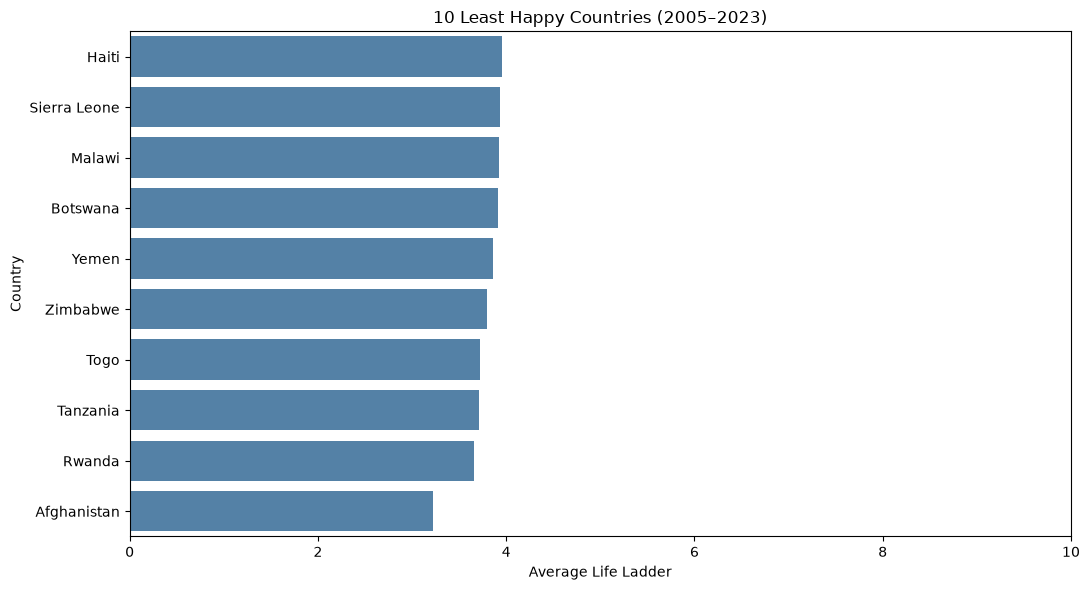

In [11]:
bottom10_historical = happiness_ranking.tail(10).reset_index()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=bottom10_historical,
    x="mean_happiness",
    y="Country name",
    color="steelblue"
)

plt.title("10 Least Happy Countries (2005–2023)")
plt.xlabel("Average Life Ladder")
plt.ylabel("Country")
plt.xlim(0, 10)

plt.tight_layout()
plt.show()

## 2.1. Happiness Rankings
The happiest countries for the last available year 2023

In [12]:
df_2023 = df[df["year"] == 2023].copy()

print(df_2023.shape)

(138, 11)


In [13]:
top10_2023 = (
    df_2023
    .sort_values("Life Ladder", ascending=False)
    .head(10)
).reset_index()

print(top10_2023[["Country name", "Life Ladder"]])

  Country name  Life Ladder
0      Finland        7.699
1      Iceland        7.562
2      Denmark        7.504
3   Costa Rica        7.384
4  Netherlands        7.255
5       Norway        7.249
6       Sweden        7.161
7       Kuwait        7.130
8    Australia        7.025
9   Luxembourg        7.016


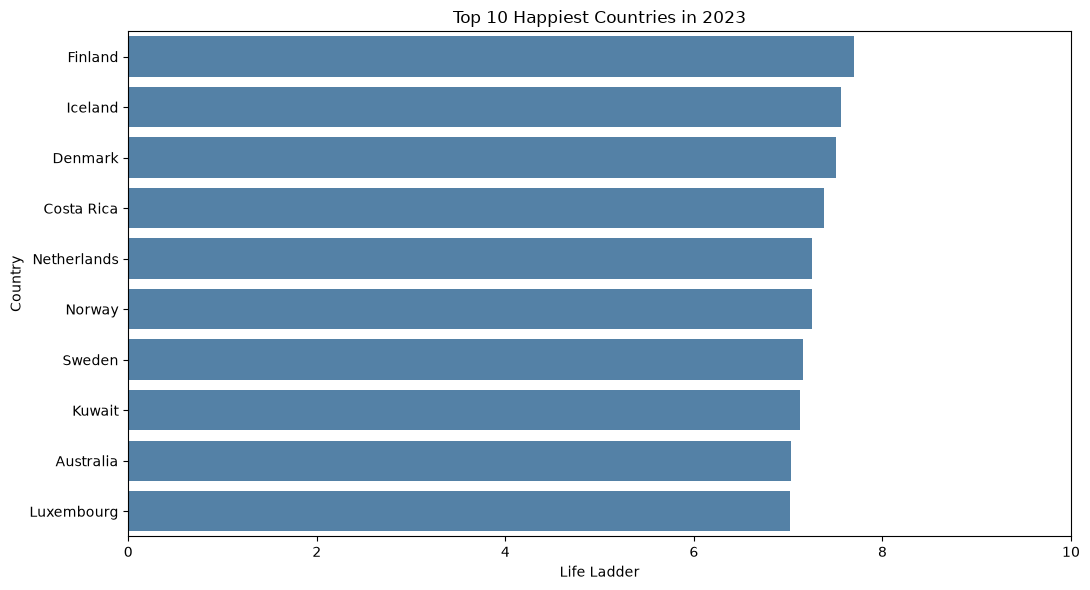

In [14]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top10_2023,
    x="Life Ladder",
    y="Country name",
    color="steelblue"
)

plt.title("Top 10 Happiest Countries in 2023")
plt.xlabel("Life Ladder")
plt.ylabel("Country")
plt.xlim(0, 10)

plt.tight_layout()
plt.show()

Denmark holds the highest average Life Ladder score across the entire 2005–2023 period (7.664), ranking third in 2023 (7.504). Meanwhile, Finland ranks first in 2023 (7.699) and second overall across the full period (7.624).

In [15]:
last10_2023 = (
    df_2023
    .sort_values("Life Ladder", ascending=True)
    .head(10)
).reset_index()

print(last10_2023[["Country name", "Life Ladder"]])

       Country name  Life Ladder
0       Afghanistan        1.446
1            Malawi        3.272
2          Botswana        3.332
3  Congo (Kinshasa)        3.383
4      Sierra Leone        3.467
5             Yemen        3.532
6          Zimbabwe        3.572
7           Lebanon        3.588
8           Comoros        3.588
9         Sri Lanka        3.602


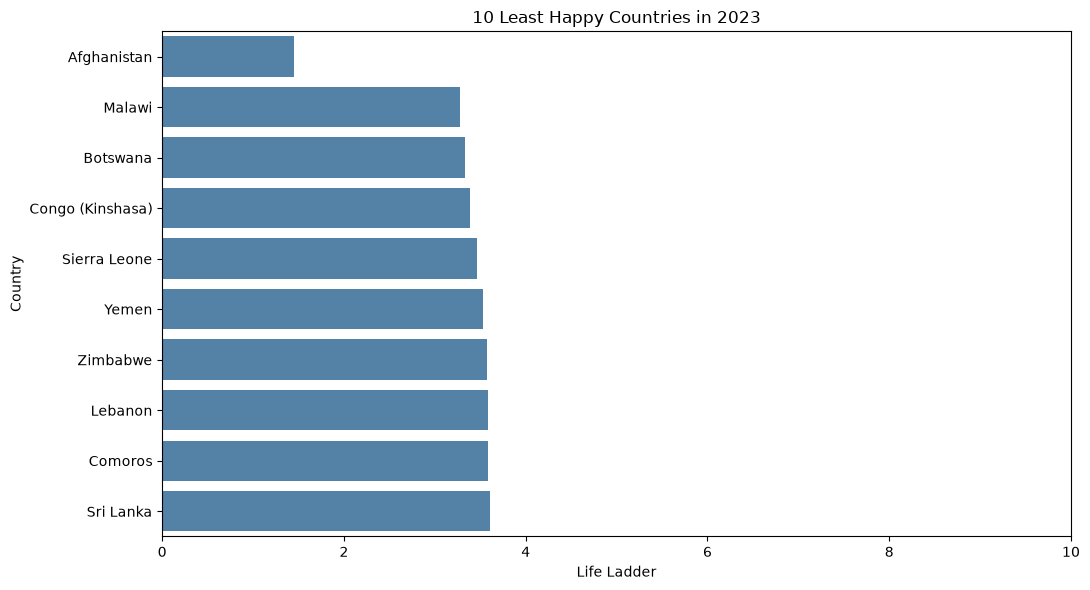

In [16]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=last10_2023,
    x="Life Ladder",
    y="Country name",
    color="steelblue"
)

plt.title("10 Least Happy Countries in 2023")
plt.xlabel("Life Ladder")
plt.ylabel("Country")
plt.xlim(0, 10)

plt.tight_layout()
plt.show()

## 2.2. Comparison
avg 2005-2023 & 2023

In [17]:
average_happiness = (
    df.groupby("Country name")["Life Ladder"]
    .mean()
    .rename("Historical Average")
)

comparison = (
    df_2023[["Country name", "Life Ladder"]]
    .merge(
        average_happiness,
        on="Country name",
        how="left"
    )
)

print(comparison.isnull().sum())

comparison["Difference"] = (
    comparison["Life Ladder"] - comparison["Historical Average"]
)

comparison = comparison.sort_values(
    "Difference", ascending=False
)

print(comparison.head(10))

Country name          0
Life Ladder           0
Historical Average    0
dtype: int64
    Country name  Life Ladder  Historical Average  Difference
63        Kosovo        6.878            5.829529    1.048471
3        Armenia        5.679            4.679529    0.999471
22         China        6.145            5.160412    0.984588
107       Serbia        6.441            5.463750    0.977250
42       Georgia        5.351            4.432500    0.918500
134      Vietnam        6.325            5.437556    0.887444
85    Mozambique        5.704            4.826455    0.877545
15      Bulgaria        5.590            4.751933    0.838067
100  Philippines        6.184            5.354111    0.829889
64        Kuwait        7.130            6.376846    0.753154


In [18]:
comparison1 = comparison.sort_values(
    "Difference", ascending=True
)

print(comparison1.head(10))

         Country name  Life Ladder  Historical Average  Difference
0         Afghanistan        1.446            3.219933   -1.773933
68            Lebanon        3.588            4.471944   -0.883944
26   Congo (Kinshasa)        3.383            4.137700   -0.754700
60             Jordan        4.292            5.044222   -0.752222
136            Zambia        3.686            4.365882   -0.679882
115         Sri Lanka        3.602            4.263412   -0.661412
74             Malawi        3.272            3.928000   -0.656000
13           Botswana        3.332            3.908786   -0.576786
96           Pakistan        4.549            5.110333   -0.561333
34              Egypt        3.881            4.437944   -0.556944


Difference represents the gap between each country's 2023 Life Ladder score and its historical average over the 2005–2023 period.

## 3. Life Satisfaction Trends

In [19]:
global_yearly_stats = (
    df.groupby("year")["Life Ladder"]
    .agg(
        mean_happiness="mean",
        median_happiness="median",
        std_happiness="std",
        countries="count"
    )
    .reset_index()
)

print(global_yearly_stats.round(3))

    year  mean_happiness  median_happiness  std_happiness  countries
0   2005           6.446             6.620          0.919         27
1   2006           5.197             5.084          1.095         89
2   2007           5.418             5.222          1.048        102
3   2008           5.419             5.182          1.169        110
4   2009           5.458             5.360          1.030        114
5   2010           5.497             5.460          1.126        124
6   2011           5.424             5.224          1.084        146
7   2012           5.444             5.309          1.121        141
8   2013           5.393             5.245          1.185        136
9   2014           5.386             5.323          1.159        144
10  2015           5.401             5.331          1.119        142
11  2016           5.396             5.417          1.144        141
12  2017           5.460             5.553          1.141        147
13  2018           5.499          

To reduce the effect of changing country coverage, I compare yearly averages with a balanced panel of countries that have observations for every year from 2011 to 2019.

In [20]:
period_df = df[df["year"].between(2011, 2019)].copy()

country_counts = (
    period_df.groupby("Country name")["year"]
    .nunique()
)

complete_countries = country_counts[
    country_counts == 9
].index

balanced_df = period_df[
    period_df["Country name"].isin(complete_countries)
].copy()

balanced_trend = (
    balanced_df.groupby("year")["Life Ladder"]
    .mean()
    .reset_index(name="mean_happiness")
)
balanced_trend

,year,mean_happiness
0,2011,5.526833
1,2012,5.457044
2,2013,5.427772
3,2014,5.468298
4,2015,5.449070
5,2016,5.468272
6,2017,5.553298
7,2018,5.606658
8,2019,5.636640


Here I show the trend of yearly averages across all available countries for the 2011–2019 period, followed by the same comparison for countries present in all 9 years.

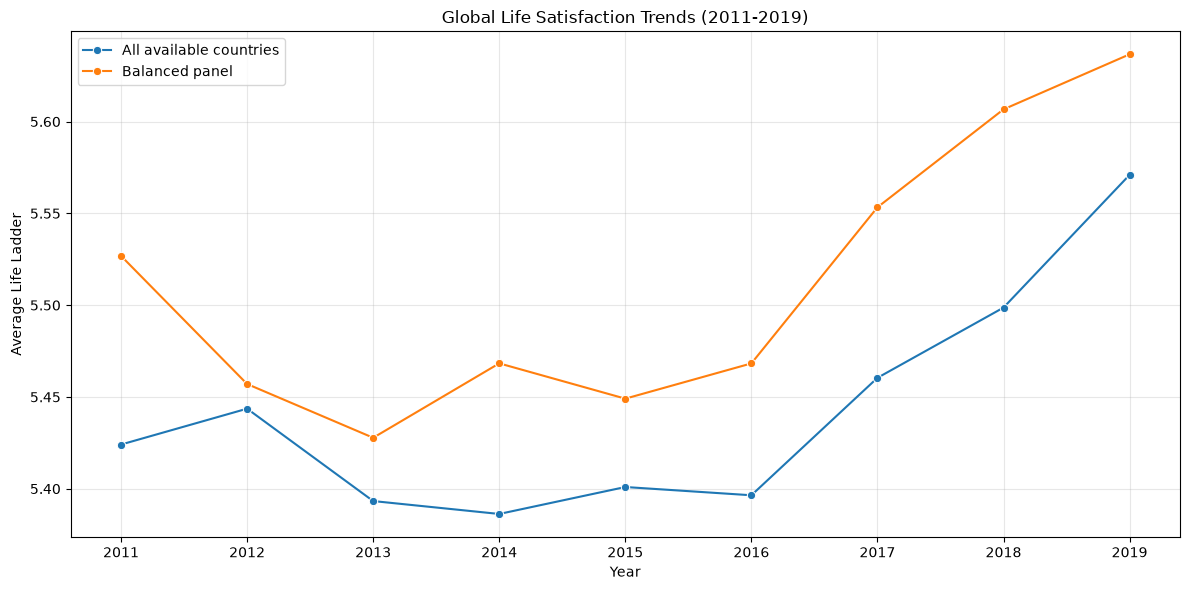

In [21]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=global_yearly_stats[
        global_yearly_stats["year"].between(2011, 2019)
    ],
    x="year",
    y="mean_happiness",
    marker="o",
    label="All available countries"
)

sns.lineplot(
    data=balanced_trend,
    x="year",
    y="mean_happiness",
    marker="o",
    label="Balanced panel"
)

plt.title("Global Life Satisfaction Trends (2011-2019)")
plt.xlabel("Year")
plt.ylabel("Average Life Ladder")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 3.1. Comparison 2011 & 2023

Across the 127 countries present in both 2011 and 2023, the average Life Ladder score increased by +0.154 points in 2023 compared to 2011 (from roughly 5.476 to 5.630).

In [27]:
endpoints = (
    df[df["year"].isin([2011, 2023])]
    .pivot(
        index="Country name",
        columns="year",
        values="Life Ladder"
    )
    .dropna()
)

endpoints["change"] = (
    endpoints[2023] - endpoints[2011]
)

print(endpoints[[2011, 2023, "change"]].head())
print()

print("Average change per country:", endpoints["change"].mean())
print()

print(endpoints[endpoints["change"] == endpoints["change"].max()])
print()

print(endpoints[endpoints["change"] == endpoints["change"].min()])

year           2011   2023  change
Country name                      
Afghanistan   3.832  1.446  -2.386
Albania       5.867  5.445  -0.422
Argentina     6.776  6.393  -0.383
Armenia       4.260  5.679   1.419
Australia     7.406  7.025  -0.381

Average change per country: 0.15400787401574803

year          2011   2023  change
Country name                     
Kosovo        4.86  6.878   2.018

year           2011   2023  change
Country name                      
Afghanistan   3.832  1.446  -2.386


In [123]:
increased = (endpoints["change"] > 0).sum()
decreased = (endpoints["change"] < 0).sum()
unchanged = (endpoints["change"] == 0).sum()

print(f"Increased: {increased}")
print(f"Decreased: {decreased}")
print(f"Unchanged: {unchanged}")

Increased: 76
Decreased: 51
Unchanged: 0


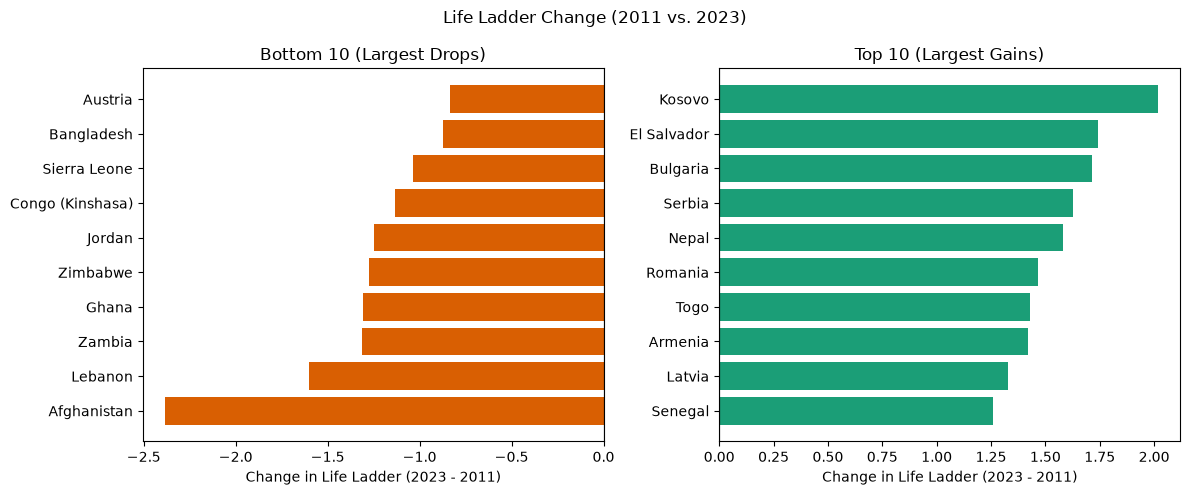

In [42]:
top_10 = endpoints.nlargest(10, "change").sort_values("change")
bottom_10 = endpoints.nsmallest(10, "change").sort_values("change")


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].barh(bottom_10.index, bottom_10["change"], color="#d95f02")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Bottom 10 (Largest Drops)")
axes[0].set_xlabel("Change in Life Ladder (2023 - 2011)")


axes[1].barh(top_10.index, top_10["change"], color="#1b9e77")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Top 10 (Largest Gains)")
axes[1].set_xlabel("Change in Life Ladder (2023 - 2011)")

plt.suptitle("Life Ladder Change (2011 vs. 2023)")
plt.tight_layout()
plt.show()

## 4. GDP and Life Satisfaction

In [46]:
gdp_2023 = (
    df.loc[
        df["year"] == 2023,
        ["Country name", "Log GDP per capita", "Life Ladder"]
    ]
    .dropna()
    .copy()
)

print(gdp_2023.shape)
print(gdp_2023.describe().round(3))

(129, 3)
       Log GDP per capita  Life Ladder
count             129.000      129.000
mean                9.517        5.647
std                 1.152        1.091
min                 7.076        3.272
25%                 8.620        4.676
50%                 9.637        5.861
75%                10.504        6.489
max                11.676        7.699


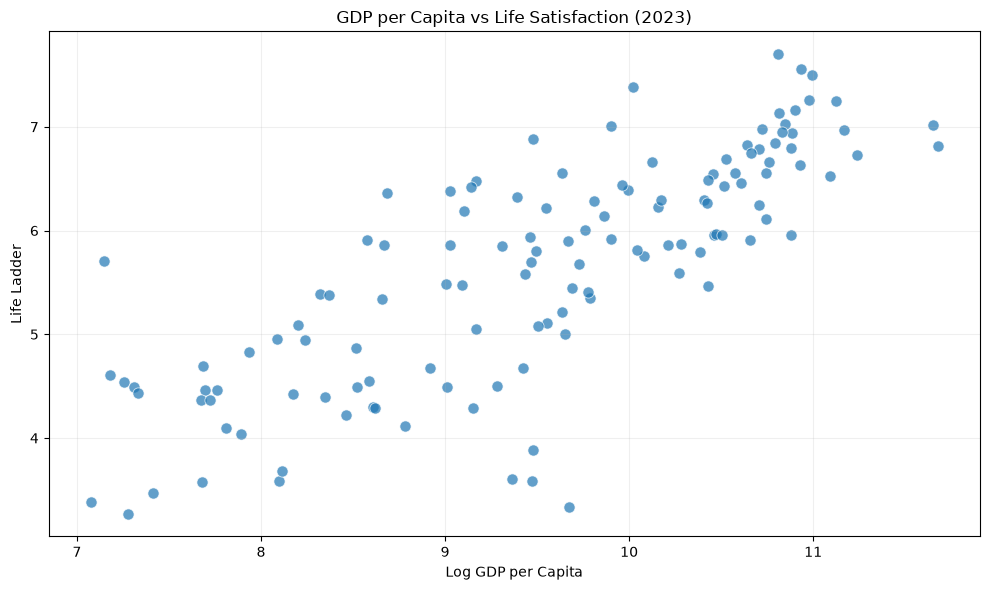

In [48]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=gdp_2023,
    x="Log GDP per capita",
    y="Life Ladder",
    alpha=0.7,
    s=65
)

plt.title("GDP per Capita vs Life Satisfaction (2023)")
plt.xlabel("Log GDP per Capita")
plt.ylabel("Life Ladder")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [127]:
pearson_corr = gdp_2023[
    ["Log GDP per capita", "Life Ladder"]
].corr(method="pearson")

print(pearson_corr)

                    Log GDP per capita  Life Ladder
Log GDP per capita            1.000000     0.782755
Life Ladder                   0.782755     1.000000


The scatter plot shows a general upward trend—higher Log GDP per capita values are typically accompanied by higher Life Ladder scores. This is supported by the correlation coefficient (r = 0.783). While we cannot claim a causal effect where higher GDP necessarily drives higher Life Ladder scores, the data confirms a strong positive correlation between the two.

The correlation between these two columns is consistently high across all years (generally between 0.68 and 0.84).

In [128]:
yearly_corr = (
    df.groupby("year")
    .apply(
        lambda group: group["Log GDP per capita"]
        .corr(group["Life Ladder"]),
        include_groups=False
    )
    .reset_index(name="Pearson Correlation")
)

print(yearly_corr.round(3))

    year  Pearson Correlation
0   2005                0.681
1   2006                0.832
2   2007                0.784
3   2008                0.839
4   2009                0.728
5   2010                0.765
6   2011                0.764
7   2012                0.781
8   2013                0.778
9   2014                0.789
10  2015                0.813
11  2016                0.829
12  2017                0.779
13  2018                0.766
14  2019                0.742
15  2020                0.767
16  2021                0.792
17  2022                0.776
18  2023                0.783


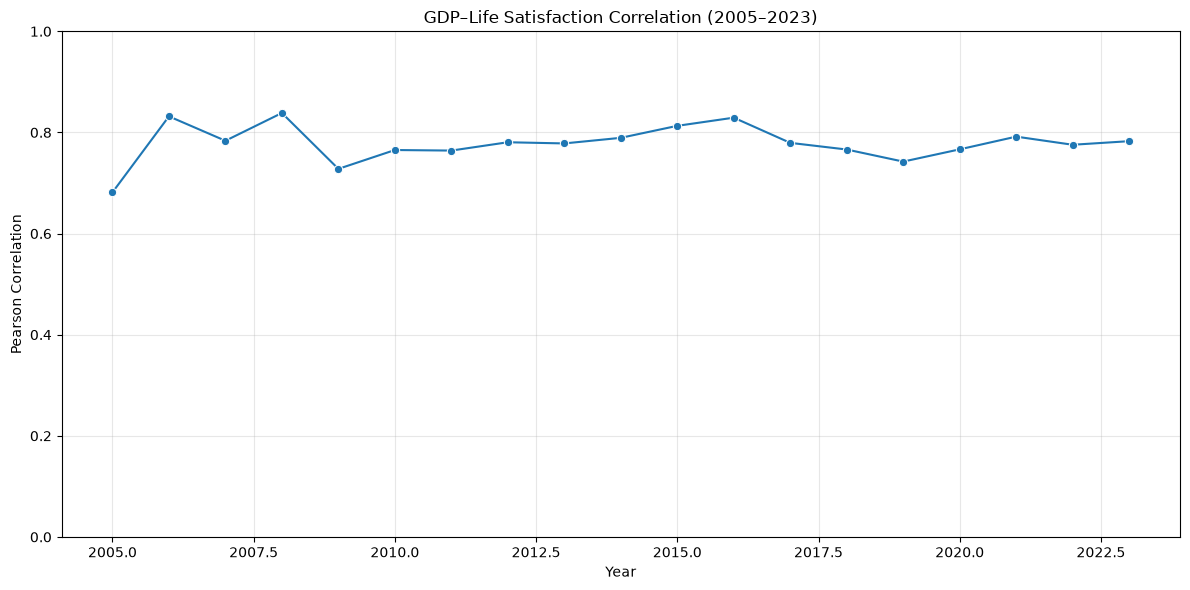

In [129]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_corr,
    x="year",
    y="Pearson Correlation",
    marker="o"
)

plt.title("GDP–Life Satisfaction Correlation (2005–2023)")
plt.xlabel("Year")
plt.ylabel("Pearson Correlation")
plt.ylim(0, 1)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Social Factors and Life Satisfaction

In [49]:
num_cols = [
    "Life Ladder",
    "Log GDP per capita",
    "Social support",
    "Healthy life expectancy at birth",
    "Freedom to make life choices",
    "Generosity",
    "Perceptions of corruption",
    "Positive affect",
    "Negative affect",
]

In [50]:
corr_matrix_2023 = df_2023[num_cols].corr(method="pearson")

In [51]:
corr_matrix = df[num_cols].corr(method="pearson")

Based on the 2023 data, Social support (0.792), Log GDP per capita (0.783), and Healthy life expectancy at birth (0.753) show the strongest positive correlation with Life Ladder.

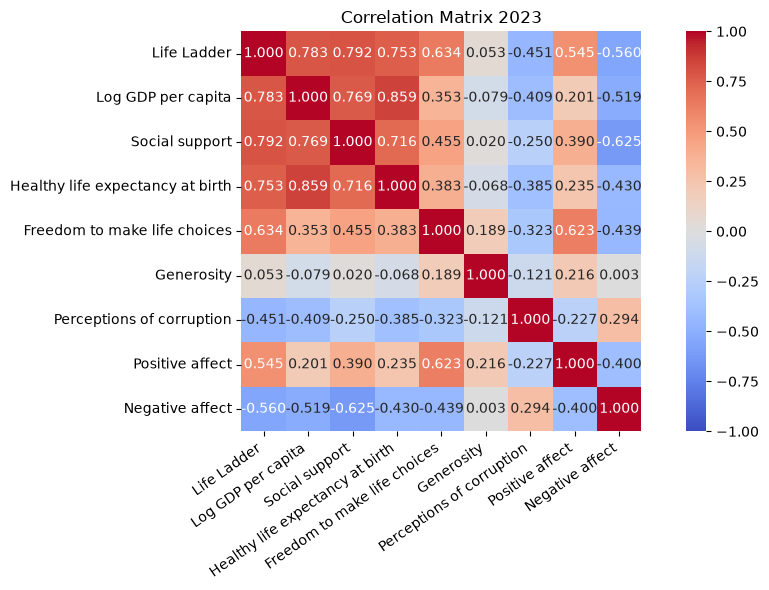

In [52]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    corr_matrix_2023,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Correlation Matrix 2023")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

Across the entire dataset (all years), the order shifts slightly: Log GDP per capita (0.784) leads in positive correlation with Life Ladder, followed by Social support (0.723) and Healthy life expectancy at birth (0.715).

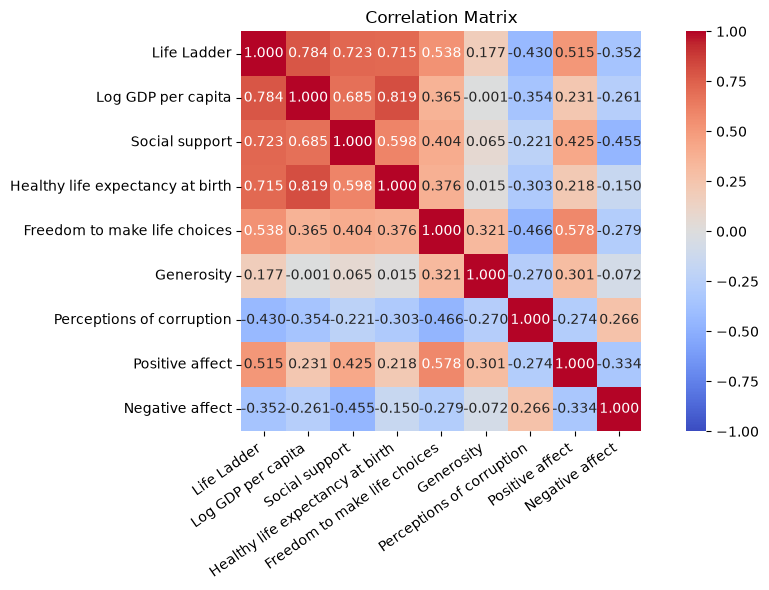

In [56]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Correlation Matrix")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

Freedom to make life choices and Positive affect also show moderately strong positive correlations with Life Ladder, while Generosity has only a weak correlation overall (0.177) and is close to zero (0.053) in 2023. Meanwhile, Perceptions of corruption and Negative affect correlate negatively with Life Ladder.

## 6. COVID-19 Period Analysis

In [57]:
covid_df = df[df["year"].between(2017, 2021)].copy()

columns = ["Life Ladder", "Negative affect"]

covid_yearly_stats = (
    covid_df.groupby("year")[columns]
    .mean()
)

In [58]:
covid_df = df[df["year"].between(2017,2021)].copy()

columns = ["Life Ladder", "Negative affect"]

covid_yearly_stats = (
    covid_df.groupby("year")[columns]
    .mean()
)

print(covid_yearly_stats.round(3))

      Life Ladder  Negative affect
year                              
2017        5.460            0.291
2018        5.499            0.293
2019        5.571            0.287
2020        5.728            0.302
2021        5.636            0.290


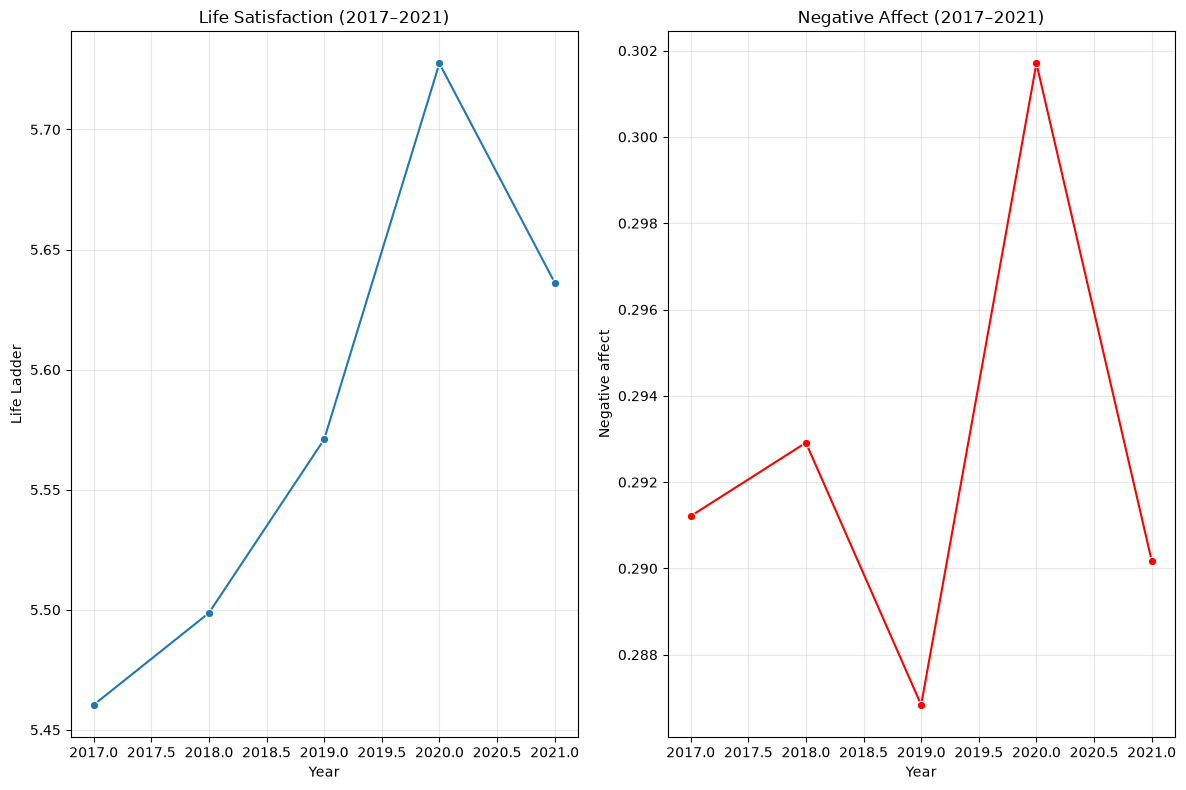

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(12, 8))

sns.lineplot(
    data=covid_yearly_stats,
    x=covid_yearly_stats.index,
    y="Life Ladder",
    marker="o",
    ax=axes[0]
)

sns.lineplot(
    data=covid_yearly_stats,
    x=covid_yearly_stats.index,
    y="Negative affect",
    marker="o",
    color="red",
    ax=axes[1]
)

axes[0].set_title("Life Satisfaction (2017–2021)")
axes[1].set_title("Negative Affect (2017–2021)")

for ax in axes:
    ax.set_xlabel("Year")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [66]:
country_counts = (
    covid_df.groupby("Country name")["year"]
    .nunique()
)

countries = country_counts[
    country_counts == 5
].index

balanced_df = covid_df[
    covid_df["Country name"].isin(countries)
].copy()

print(balanced_df["Country name"].nunique())

106


Filtering for countries present in all 5 years reverses the 2019–2020 Life Ladder shift from a slight rise to a slight drop due to changes in which countries are included each year.

In [138]:
columns = ["Life Ladder", "Negative affect"]

balanced_yearly = (
    balanced_df.groupby("year")[columns]
    .mean()
)

print(balanced_yearly.round(3))

      Life Ladder  Negative affect
year                              
2017        5.684            0.276
2018        5.741            0.281
2019        5.748            0.279
2020        5.721            0.302
2021        5.677            0.285


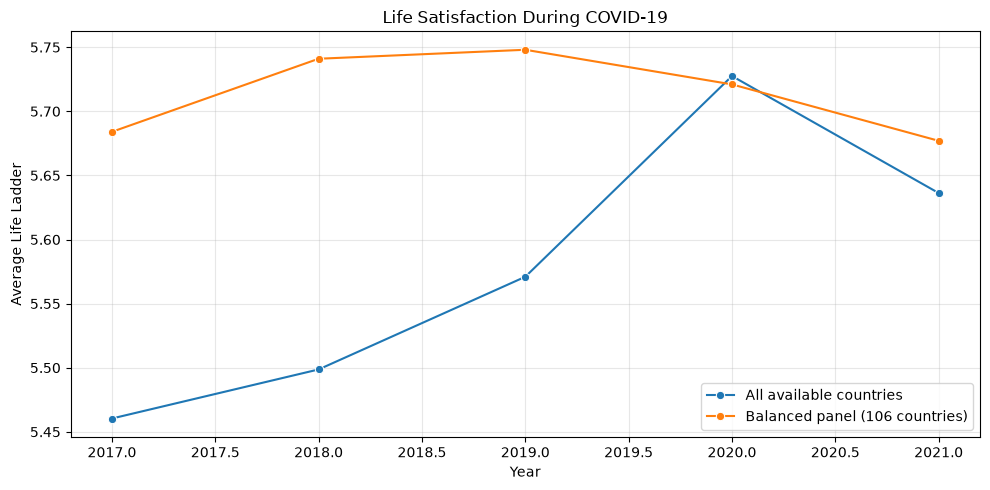

In [69]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=covid_yearly_stats,
    x=covid_yearly_stats.index,
    y="Life Ladder",
    marker="o",
    label="All available countries"
)

sns.lineplot(
    data=balanced_yearly,
    x=balanced_yearly.index,
    y="Life Ladder",
    marker="o",
    label="Balanced panel (106 countries)"
)

plt.title("Life Satisfaction During COVID-19")
plt.xlabel("Year")
plt.ylabel("Average Life Ladder")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [72]:
pre_covid = (
    balanced_df[balanced_df["year"] <= 2019]
    .groupby("Country name")[columns]
    .mean()
)

during_covid = (
    balanced_df[balanced_df["year"] >= 2020]
    .groupby("Country name")[columns]
    .mean()
)

changes = during_covid - pre_covid
print(changes.mean().round(3))

Life Ladder       -0.025
Negative affect    0.015
dtype: float64


This shows a slight drop in life satisfaction (Life Ladder) during the COVID period compared to pre-COVID years, alongside a slight rise in negative affect.

## 7. Key Findings

The exploratory data analysis of the World Happiness Report dataset for the period 2005–2023 revealed several important patterns in global life satisfaction and its relationship with economic and social indicators.

1. Happiness Rankings

Denmark recorded the highest historical average Life Ladder score (7.664), followed by Finland (7.624), among countries with at least ten annual observations.

Finland ranked first in 2023 with a Life Ladder score of 7.699.

Nordic countries consistently ranked among the happiest countries.

Afghanistan recorded both the lowest historical average (3.220) among eligible countries and the lowest Life Ladder score in 2023 (1.446).

2. Life Satisfaction Trends

Life satisfaction showed a modest upward trend among countries consistently represented between 2011 and 2019.

Among the 127 countries present in both 2011 and 2023, the average Life Ladder score increased by 0.154 points.

Life satisfaction increased in 76 countries (59.8%) and decreased in 51 countries (40.2%).

Kosovo recorded the largest increase (+2.018), while Afghanistan experienced the largest decrease (-2.386).

3. Economic Factors

Log GDP per capita showed a consistently strong positive correlation with life satisfaction throughout the observed period.

The yearly Pearson correlation coefficients ranged from approximately 0.681 to 0.839.

In 2023, the Pearson correlation coefficient between Log GDP per capita and Life Ladder was 0.783.

These results suggest a strong association between economic prosperity and life satisfaction, although they do not establish a causal relationship.

4. Social Factors

The strongest positive correlations with Life Ladder in 2023 were observed for:

Social support (0.792)

Log GDP per capita (0.783)

Healthy life expectancy at birth (0.753)

Freedom to make life choices and Positive affect also showed positive relationships with life satisfaction.

Perceptions of corruption and Negative affect were negatively correlated with Life Ladder, while Generosity showed a relatively weak correlation.

These findings suggest that life satisfaction is associated with both economic conditions and broader social and emotional factors.

5. COVID-19 Period

The analysis of all available countries initially suggested an increase in average life satisfaction between 2019 and 2020.

However, restricting the analysis to a balanced panel of 106 countries revealed a slight decrease from 5.748 to 5.721.

Comparing the pre-pandemic period (2017–2019) with the pandemic period (2020–2021), the average Life Ladder score decreased by 0.025 points, while Negative affect increased by 0.015.

This demonstrates the importance of consistent country coverage when comparing changes over time.

## 7.1. Conclusion

This exploratory data analysis provides insights into life satisfaction across countries between 2005 and 2023.

The results indicate that economic prosperity, social support, and healthy life expectancy are among the indicators most strongly associated with higher life satisfaction. However, economic factors alone do not fully explain differences in happiness across countries.

Overall, the project shows that life satisfaction is a multidimensional phenomenon associated with a combination of economic, social, and emotional factors.